# 04 · Negative Binomial Regression

A count model for lanternfly sightings per county-year, compared with notebook 03's regularized linear models and the baselines.

**Why a count model?** The response is a count with 88% zeros and variance far above the mean (*overdispersion*). Notebook 03 models `log1p(count)` with linear regression; a GLM models the count directly:

- **Poisson GLM:** log(E[count]) = Xβ, and assumes variance = mean.
- **Negative binomial (NB2):** same mean, but variance = mean + α·mean², so α > 0 allows overdispersion.

**Shared setup:** data, split and metrics come from `src/modeling.py` (`build_model_table`, `split`, `scores`) and results are appended to `experiments/experiment_log.csv` with `log_experiment`. The table reproduces notebook 03's exactly (8,790 rows; train 2015–2022, test 2023–2025), so results are directly comparable.

> **AI-generated code (Claude Code).** See `docs/ai_usage.md`. *Team interpretation* cells are for the team to write.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.linear_model import ElasticNetCV, LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import modeling as m

warnings.filterwarnings("ignore", category=RuntimeWarning)   # NB likelihood overflows at extreme trial steps
# A failed first (Newton) attempt warns before fit_nb retries with BFGS; the table reports final convergence.
from statsmodels.tools.sm_exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)
NOTEBOOK = "04_negative_binomial"
SEED = 6021

## 1. Modeling table and split

In [2]:
df, steps = m.build_model_table()
train, test = m.split(df)
print(f"\ntrain: {len(train):,} rows ({train['year'].min()}-{train['year'].max()}), "
      f"test: {len(test):,} rows ({test['year'].min()}-{test['year'].max()})")
for name, feats in m.FEATURE_SETS.items():
    print(f"Feature set {name} ({len(feats)}): {', '.join(feats)}")

                             step  rows
       all county-years 2014-2025 35827
           in invasion region box 16811
         with >= 200 observations  8956
            with complete climate  8941
in train + test years (2015-2025)  8790

train: 5,309 rows (2015-2022), test: 3,481 rows (2023-2025)
Feature set A (7): log_effort, tavg_annual, tmin_winter, tmax_summer, precip_annual, lat, lon
Feature set B (8): log_effort, tavg_annual, tmin_winter, tmax_summer, precip_annual, lat, lon, lag_log_count
Feature set C (21): log_effort, tavg_annual, tmin_winter, tmax_summer, precip_annual, lat, lon, lag_log_count, log_toh_rate_train, fia_toh_present, fia_missing, rail_km_per_km2, interstate_km_per_km2, is_metro, has_interstate, div_middle_atlantic, div_new_england, div_east_north_central, div_east_south_central, div_west_north_central, div_west_south_central


**Distribution shift.** The invasion grows over time, so test years look different from training years. A model has to extrapolate:

In [3]:
shift = df.groupby("year").agg(split=("split", "first"), mean_count=("slf_obs", "mean"),
                              share_zero=("slf_obs", lambda s: (s == 0).mean()), rows=("slf_obs", "size"))
shift.round(3)

,split,mean_count,share_zero,rows
year,,,,
2015,train,0.000,1.000,183
2016,train,0.010,0.993,298
2017,train,0.057,0.990,404
2018,train,0.308,0.980,548
2019,train,1.057,0.961,789
2020,train,2.593,0.946,965
2021,train,4.148,0.916,1041
2022,train,5.697,0.874,1081
2023,test,7.976,0.842,1114


## 2. Is a Poisson model enough?

If Poisson were adequate, the Pearson dispersion (χ² / residual df) would be near 1 and NB's α near 0. The likelihood-ratio (LR) test compares the two (NB nests Poisson at α = 0).

In [4]:
def design(feats):
    sc = StandardScaler().fit(train[feats])     # fit on training years only
    return sm.add_constant(sc.transform(train[feats])), sm.add_constant(sc.transform(test[feats]))

def fit_nb(Xtr, ytr):
    """NB2 by maximum likelihood, started from the Poisson solution for stability."""
    pois = sm.GLM(ytr, Xtr, family=sm.families.Poisson()).fit()
    model = sm.NegativeBinomial(ytr, Xtr, loglike_method="nb2")
    res = model.fit(start_params=np.append(np.asarray(pois.params), 1.0), method="newton", maxiter=200, disp=0)
    if not res.mle_retvals["converged"]:
        res = model.fit(start_params=np.asarray(res.params), method="bfgs", maxiter=5000, disp=0)
    return pois, res

ytr = train["slf_obs"].to_numpy()
fits, rows = {}, []
for fs, feats in m.FEATURE_SETS.items():
    Xtr, Xte = design(feats)
    pois, nb = fit_nb(Xtr, ytr)
    fits[fs] = (pois, nb, Xtr, Xte, feats)
    lr = 2 * (nb.llf - pois.llf)
    rows.append({"features": fs, "poisson_dispersion": pois.pearson_chi2 / pois.df_resid,
                 "nb_alpha": np.asarray(nb.params)[-1], "LR_stat": lr,
                 "AIC_poisson": pois.aic, "AIC_nb": nb.aic, "nb_converged": nb.mle_retvals["converged"]})
pd.DataFrame(rows).round(2)

,features,poisson_dispersion,nb_alpha,LR_stat,AIC_poisson,AIC_nb,nb_converged
0,A,43.69,22.23,48757.41,53104.57,4349.16,True
1,B,9.29,10.01,17240.44,21262.03,4023.59,True
2,C,5.18,5.09,11700.93,15371.50,3672.57,True


Dispersion far above 1, large α, huge LR statistics and much lower AIC all say the same thing: **the data are strongly overdispersed, and Poisson is not adequate.** The rest of the notebook uses NB.

## 3. Scoring on a comparable scale

Notebook 03 scores predictions of `log1p(count)`. NB predicts a whole *distribution* of counts. With α between 5 and 22 that distribution is very skewed: mostly zeros plus a long tail, so its **mean** is pulled up by rare huge values and `log1p(mean)` is a poor point prediction.

The fair counterpart to a model fitted on `log1p(count)` is the NB model's **expected log1p(count)**, E[log(1 + Y)]. It has no closed form, so it is estimated by simulating 4,000 draws from each row's predicted distribution (fixed seed). Count-scale MAE uses each row's predicted **median**.

In [5]:
rng = np.random.default_rng(SEED)

def nb_predictions(res, X, draws=4000):
    p = np.asarray(res.params)
    mu, alpha = np.exp(X @ p[:-1]), p[-1]
    size = 1 / alpha
    sims = rng.negative_binomial(size, (size / (size + mu))[:, None], size=(len(mu), draws))
    return {"mu": mu, "elog1p": np.log1p(sims).mean(axis=1), "median": np.median(sims, axis=1),
            "p_zero": (1 / (1 + alpha * mu)) ** (1 / alpha)}

preds = {fs: (nb_predictions(nb, Xtr), nb_predictions(nb, Xte)) for fs, (_, nb, Xtr, Xte, _) in fits.items()}
print("Largest predicted mean count on the test years, by feature set:",
      {fs: f"{te['mu'].max():,.0f}" for fs, (tr_, te) in preds.items()})

Largest predicted mean count on the test years, by feature set: {'A': '16,347', 'B': '3,503,484', 'C': '388,405'}


The largest predicted means are far above anything observed (the largest test count is under 2,000). That is the exponential link extrapolating the training-year trend into the larger test-year invasion, which is the main weakness diagnosed below.

## 4. Results vs. notebook 03 and the baselines

Baselines and notebook 03's Elastic Net (feature set B, its best model) are recomputed here on the shared table, so every row below uses identical data. Elastic Net reproduces notebook 03's reported test RMSE (0.525) and MAE (0.251).

In [6]:
yte, cte = test["y"].to_numpy(), test["slf_obs"].to_numpy()
results = {}

# Baselines (same definitions as notebook 03)
results[("Baseline: training mean", "-")] = m.scores(yte, np.full(len(test), train["y"].mean()), cte, np.full(len(test), np.expm1(train["y"].mean())))
eo = LinearRegression().fit(train[["log_effort"]], train["y"])
p = eo.predict(test[["log_effort"]]); results[("Baseline: effort only (OLS)", "-")] = m.scores(yte, p, cte, np.expm1(p))
p = test["lag_log_count"].to_numpy(); results[("Baseline: persistence", "-")] = m.scores(yte, p, cte, np.expm1(p))

# Notebook 03's best model, reproduced on the shared table
cv = [(np.flatnonzero(train["year"] < v), np.flatnonzero(train["year"] == v)) for v in range(2019, 2023)]
en = make_pipeline(StandardScaler(), ElasticNetCV(alphas=np.logspace(-6, 3, 80), l1_ratio=[.1, .5, .9], cv=cv, max_iter=50_000))
en.fit(train[m.FEATURE_SETS["B"]], train["y"])
p_en = en.predict(test[m.FEATURE_SETS["B"]]); results[("ElasticNet", "B")] = m.scores(yte, p_en, cte, np.expm1(p_en))

for fs, (_, te) in preds.items():
    results[("Negative binomial", fs)] = m.scores(yte, te["elog1p"], cte, te["median"])

table = pd.DataFrame(results).T.rename_axis(["model", "features"])
table.round(3)

test_RMSE  test_MAE  test_R2  \
model                       features                                 
Baseline: training mean     -             1.351     0.643   -0.096   
Baseline: effort only (OLS) -             1.242     0.639    0.073   
Baseline: persistence       -             0.556     0.214    0.814   
ElasticNet                  B             0.525     0.251    0.835   
Negative binomial           A             1.254     0.532    0.054   
                            B             0.742     0.312    0.669   
                            C             0.774     0.307    0.640   

                                      test_MAE_count  
model                       features                  
Baseline: training mean     -                 11.100  
Baseline: effort only (OLS) -                 11.095  
Baseline: persistence       -                  6.878  
ElasticNet                  B                  9.449  
Negative binomial           A                 11.003  
                            B                 22.322  
                            C                 36.509

In [7]:
# Record every run in the shared experiment log
n_tr, n_te = len(train), len(test)
notes = {("Baseline: training mean", "-"): "shared baseline",
         ("Baseline: effort only (OLS)", "-"): "shared baseline",
         ("Baseline: persistence", "-"): "shared baseline: last year's log1p count",
         ("ElasticNet", "B"): "notebook 03's best model, reproduced on the shared table"}
for (model, fs), met in results.items():
    nb_note = (f"NB2 MLE; alpha={np.asarray(fits[fs][1].params)[-1]:.2f}; log1p scored as simulated E[log1p Y]; count MAE from median"
               if model == "Negative binomial" else notes[(model, fs)])
    nbk = "03_regularized_regression" if model == "ElasticNet" else NOTEBOOK
    m.log_experiment(nbk, model, fs, met, n_tr, n_te, nb_note)
m.read_log()

,date,notebook,model,feature_set,train_years,test_years,n_train,n_test,test_RMSE,test_MAE,test_R2,test_MAE_count,notes
0,2026-11-17,04_negative_binomial,Baseline: training mean,-,2015-2022,2023-2025,5309,3481,1.3509,0.6428,-0.0965,11.0998,shared baseline
1,2026-11-17,04_negative_binomial,Baseline: effort only (OLS),-,2015-2022,2023-2025,5309,3481,1.2419,0.6386,0.0733,11.0946,shared baseline
2,2026-11-17,04_negative_binomial,Baseline: persistence,-,2015-2022,2023-2025,5309,3481,0.5560,0.2142,0.8143,6.8776,shared baseline: last year's log1p count
3,2026-11-17,03_regularized_regression,ElasticNet,B,2015-2022,2023-2025,5309,3481,0.5248,0.2513,0.8345,9.4486,"notebook 03's best model, reproduced on the sh..."
4,2026-11-17,04_negative_binomial,Negative binomial,A,2015-2022,2023-2025,5309,3481,1.2545,0.5318,0.0544,11.0032,NB2 MLE; alpha=22.23; log1p scored as simulate...
5,2026-11-17,04_negative_binomial,Negative binomial,B,2015-2022,2023-2025,5309,3481,0.7422,0.3120,0.6690,22.3220,NB2 MLE; alpha=10.01; log1p scored as simulate...
6,2026-11-17,04_negative_binomial,Negative binomial,C,2015-2022,2023-2025,5309,3481,0.7737,0.3066,0.6404,36.5089,NB2 MLE; alpha=5.09; log1p scored as simulated...


### Error by test year

,ElasticNet_B,NB_B,persistence
year,,,
2023,0.503,0.697,0.517
2024,0.471,0.636,0.487
2025,0.589,0.867,0.645


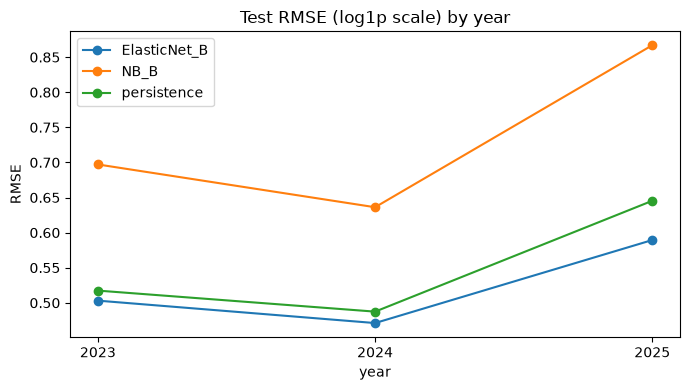

In [8]:
best_nb = min(preds, key=lambda fs: results[("Negative binomial", fs)]["test_RMSE"])
by_year = test.assign(ElasticNet_B=p_en, **{f"NB_{best_nb}": preds[best_nb][1]["elog1p"]}, persistence=test["lag_log_count"])
cols = ["ElasticNet_B", f"NB_{best_nb}", "persistence"]
rmse_year = by_year.groupby("year").apply(lambda g: pd.Series({c: np.sqrt(((g[c] - g["y"]) ** 2).mean()) for c in cols}))
ax = rmse_year.plot(marker="o", figsize=(7, 4), title="Test RMSE (log1p scale) by year")
ax.set(ylabel="RMSE", xticks=rmse_year.index); plt.tight_layout()
rmse_year.round(3)

## 5. Diagnostics

### Zeros
Does NB reproduce the share of zeros? If it under-predicts zeros on the training years, a zero-inflated or two-part (hurdle) model is worth trying.

In [9]:
zeros = pd.DataFrame({fs: {"train observed": (train["slf_obs"] == 0).mean(), "train predicted": tr_["p_zero"].mean(),
                           "test observed": (test["slf_obs"] == 0).mean(), "test predicted": te["p_zero"].mean()}
                      for fs, (tr_, te) in preds.items()}).T
zeros.round(3)

,train observed,train predicted,test observed,test predicted
A,0.939,0.939,0.793,0.950
B,0.939,0.936,0.793,0.907
C,0.939,0.935,0.793,0.905


### Predicted vs. actual (test years)

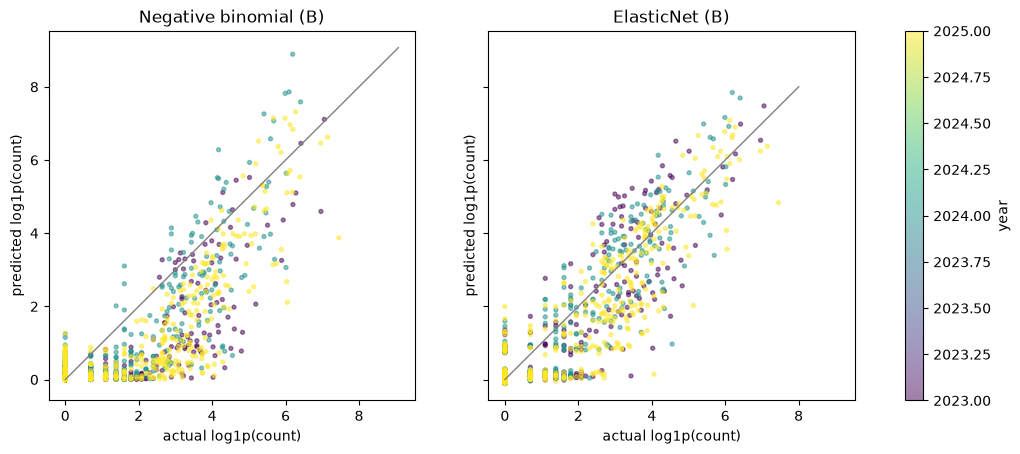

In [10]:
te_best = preds[best_nb][1]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), sharex=True, sharey=True)
for a, (name, p) in zip(ax, [(f"Negative binomial ({best_nb})", te_best["elog1p"]), ("ElasticNet (B)", p_en)]):
    sc = a.scatter(yte, p, c=test["year"], s=8, alpha=.5, cmap="viridis")
    lim = [0, max(yte.max(), p.max()) * 1.02]
    a.plot(lim, lim, color="grey", lw=1)
    a.set(title=name, xlabel="actual log1p(count)", ylabel="predicted log1p(count)")
plt.colorbar(sc, ax=ax, label="year"); plt.show()

## 6. Coefficients (best NB feature set)

Predictors are standardized, so exp(β) is the **multiplicative change in expected sightings per one standard deviation** of the predictor, holding the others fixed. 95% CIs are Wald intervals; they assume the model is correctly specified and treat county-years as independent, which spatial and temporal dependence violates, so they are optimistic.

**Multicollinearity check:** `tavg_annual` and `tmax_summer` correlate at 0.89 (notebook 03's heatmap). Large coefficients of opposite sign on a correlated pair are a typical symptom, so individual climate coefficients here should not be read on their own; this is another argument for a regularized NB.

,feature,beta,IRR_per_SD,IRR_low,IRR_high,p_value
1,tavg_annual,-2.654,0.070,0.027,0.183,0.000
5,lat,-0.192,0.826,0.463,1.471,0.516
4,precip_annual,0.098,1.103,0.885,1.375,0.384
2,tmin_winter,0.571,1.769,1.120,2.796,0.015
0,log_effort,0.946,2.574,2.186,3.032,0.000
7,lag_log_count,1.083,2.953,2.505,3.480,0.000
6,lon,1.714,5.549,4.155,7.411,0.000
3,tmax_summer,2.417,11.208,6.563,19.141,0.000


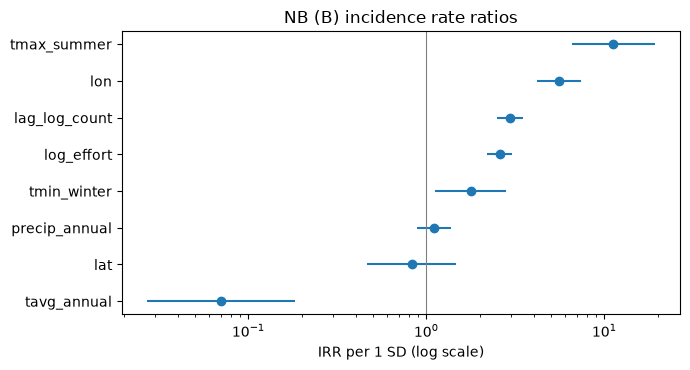

In [11]:
_, nb, _, _, feats = fits[best_nb]
params, ci = np.asarray(nb.params)[1:-1], np.asarray(nb.conf_int())[1:-1]
coef = pd.DataFrame({"feature": feats, "beta": params, "IRR_per_SD": np.exp(params),
                     "IRR_low": np.exp(ci[:, 0]), "IRR_high": np.exp(ci[:, 1]),
                     "p_value": np.asarray(nb.pvalues)[1:-1]}).sort_values("IRR_per_SD")
fig, ax = plt.subplots(figsize=(7, 0.35 * len(coef) + 1))
ax.errorbar(coef["IRR_per_SD"], coef["feature"], xerr=[coef["IRR_per_SD"] - coef["IRR_low"], coef["IRR_high"] - coef["IRR_per_SD"]], fmt="o")
ax.axvline(1, color="grey", lw=.8); ax.set(xscale="log", xlabel="IRR per 1 SD (log scale)", title=f"NB ({best_nb}) incidence rate ratios")
plt.tight_layout()
coef.round(3)

### Team interpretation
_To be written by the team. Prompts:_
- Is overdispersion the main thing notebook 03's linear model was missing? Did NB fix it on the test years?
- Why might NB do well on training years but worse on test years? (Section 1's distribution shift, the largest predicted means in section 3, the error-by-year plot.)
- Which coefficients are large and stable, and do they make biological sense?

### Next steps (suggested)
- **Regularized NB** (L2 penalty): curbs the extreme extrapolated predictions.
- **Spread features** (infested neighbors, distance to the front): may explain test-year growth better than lat/lon and climate trends.
- **Zero-inflated / hurdle model**, if section 5 shows NB under-predicting zeros.
- **Tree ensemble** (random forest / gradient boosting) as a third approach.
- Have notebook 03 call `m.log_experiment` for its own runs.